# Premier League 2025/26: Football Data Analysis

Football performance analytics has become an integral part for clubs, coaches and analysts to evaluate the strengths and weaknesses of the team. This project conducts a data-driven analysis of the English Premier League 2025/26 season, using datasets of head-to-head record and standings, and player-level stats to explore attacking and defensive performance, home and away form differences, and individual player statistics.

The analysis combines exploratory data analysis, data visualisation and statistical hypothesis testing. The notebook follows a reproducible workflow: loading and cleaning raw datasets, examining key match and player metrics, generating comparative charts, and running statistical tests to identify patterns in league performance.

## Section 1: Setup and Data Loading

**Purpose**: Configure the Python analytical environment, import the required libraries, and load the two raw datasets used throughout this project. This section establishes a reproducible foundation for the Premier League 2025/26 football data analysis that follows.

**Instruction**: Make sure the files `season-2526.csv` and `players_data-2025_2026.csv` are saved in the same directory as this notebook before running the code cells sequentially.

### Section 1.1 Import Libraries

Import Python libraries for data manipulation, numerical computation, visualisation and statistical hypothesis testing. The commented pip installation command is intended solely for troubleshooting only, execute it **only if a module import error occurs**, then restart the notebook kernel afterwards.

In [9]:
# Run this only if an import fails, then restart the kernel if needed:
# %pip install pandas numpy matplotlib seaborn scipy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_rel, t
from IPython.display import display

# Set visualisation style and pandas display settings
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 15)
print("Libraries imported successfully.")

Libraries imported successfully.


### Section 1.2 Load Datasets

Read the two raw CSV files into Pandas DataFrames. We create independent working copies of the raw datasets to avoid permanently modifying the original source data. The printed shape outputs confirm the total number of records and features loaded for player and match datasets respectively.

In [11]:
# Load raw datasets
players_raw = pd.read_csv("players_data-2025_2026.csv")
matches_raw = pd.read_csv("season-2526.csv")

# Create working copies to preserve original raw data
players = players_raw.copy()
matches = matches_raw.copy()

# Print dataset dimensions
print("Player data shape:", players.shape)
print("Match data shape:", matches.shape)

Player data shape: (2839, 102)
Match data shape: (380, 22)


## Section 2: Data Inspection and Cleaning

**Purpose**: This section performs exploratory data quality checks and targeted cleaning for both player and match datasets. The objective is to identify anomalies, filter irrelevant records, validate logical constraints, and prepare clean datasets for subsequent Premier League analysis. All operations are applied to working copies, preserving the original raw datasets intact.

### Section 2.1 Preview and Inspect Data

Examine representative sample records, column names, data types and descriptive statistics. This step verifies dataset scope, confirms the competition labels and date range, and reveals the structure of player and match-level features.

In [12]:
# Preview selected key columns from player dataset and full match dataset
display(players[["Player", "Squad", "Comp", "Pos", "MP", "Gls", "Ast"]].head())
display(matches.head())

,Player,Squad,Comp,Pos,MP,Gls,Ast
0,Brenden Aaronson,Leeds United,eng Premier League,"MF,FW",37,4,5
1,Jerome Abbey,Wolves,eng Premier League,MF,1,0,0
2,Zach Abbott,Nottingham Forest,eng Premier League,DF,3,0,0
3,Jones El-Abdellaoui,Celta Vigo,es La Liga,"MF,FW",22,2,0
4,Himad Abdelli,Marseille,fr Ligue 1,MF,8,0,0


,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,...,AF,HC,AC,HY,AY,HR,AR
0,2025-08-15,Liverpool,Bournemouth,4,2,H,1,...,10,6,7,1,2,0,0
1,2025-08-16,Aston Villa,Newcastle,0,0,D,0,...,11,3,6,1,1,1,0
2,2025-08-16,Brighton,Fulham,1,1,D,0,...,15,4,3,3,3,0,0
3,2025-08-16,Sunderland,West Ham,3,0,H,0,...,10,5,7,0,1,0,0
4,2025-08-16,Tottenham,Burnley,3,0,H,1,...,8,6,5,0,0,0,0


In [13]:
# Inspect column names, data types and league distribution
print("Player columns:", players.columns.tolist())
players[["Player", "Squad", "Comp", "Pos", "Saves", "SoTA", "GA"]].info()
matches.info()
print("Leagues in player data:")
print(players["Comp"].value_counts())

Player columns: ['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'G+A-PK', 'Rk_stats_keeper', 'Nation_stats_keeper', 'Pos_stats_keeper', 'Comp_stats_keeper', 'Age_stats_keeper', 'Born_stats_keeper', 'MP_stats_keeper', 'Starts_stats_keeper', 'Min_stats_keeper', '90s_stats_keeper', 'GA', 'GA90', 'SoTA', 'Saves', 'Save%', 'W', 'D', 'L', 'CS', 'CS%', 'PKatt_stats_keeper', 'PKA', 'PKsv', 'PKm', 'Rk_stats_shooting', 'Nation_stats_shooting', 'Pos_stats_shooting', 'Comp_stats_shooting', 'Age_stats_shooting', 'Born_stats_shooting', '90s_stats_shooting', 'Gls_stats_shooting', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'PK_stats_shooting', 'PKatt_stats_shooting', 'Rk_stats_playing_time', 'Nation_stats_playing_time', 'Pos_stats_playing_time', 'Comp_stats_playing_time', 'Age_stats_playing_time', 'Born_stats_playing_time', 'MP_stats_playing_time', 'Min_stats_playing_time', 'Mn/MP'

In [5]:
# Generate statistical summary for match and player numeric features
display(matches.describe().round(2))
display(players[["Age", "Min", "Gls", "Ast"]].describe().round(2))
print("Raw match date range:", matches.Date.min(), "to", matches.Date.max())

Raw match date range: 2025-08-15 to 2026-05-24


,FTHG,FTAG,HTHG,HTAG,HS,AS,HST,...,AF,HC,AC,HY,AY,HR,AR
count,380.00,380.00,380.00,380.00,380.00,380.00,380.00,...,380.00,380.00,380.00,380.00,380.00,380.00,380.00
mean,1.53,1.22,0.69,0.50,13.84,11.16,4.50,...,10.99,5.39,4.60,1.67,2.08,0.05,0.05
std,1.17,1.08,0.78,0.74,4.95,4.57,2.24,...,3.40,2.73,2.75,1.23,1.32,0.24,0.22
min,0.00,0.00,0.00,0.00,1.00,3.00,0.00,...,3.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,1.00,0.00,0.00,0.00,11.00,8.00,3.00,...,9.00,3.00,3.00,1.00,1.00,0.00,0.00
50%,1.00,1.00,1.00,0.00,14.00,11.00,4.00,...,11.00,5.00,4.00,2.00,2.00,0.00,0.00
75%,2.00,2.00,1.00,1.00,16.25,14.00,6.00,...,13.00,7.00,6.00,2.00,3.00,0.00,0.00
max,5.00,5.00,3.00,4.00,35.00,30.00,11.00,...,21.00,14.00,15.00,5.00,6.00,2.00,1.00


,Age,Min,Gls,Ast
count,2837.00,2839.00,2839.00,2839.00
mean,24.86,1218.58,1.66,1.16
std,4.62,963.22,2.93,1.83
min,15.00,1.00,0.00,0.00
25%,21.00,320.50,0.00,0.00
50%,25.00,1074.00,0.00,0.00
75%,28.00,1972.50,2.00,2.00
max,41.00,3420.00,36.00,21.00


### Section 2.2 Check Data Quality

Quantify missing values and duplicate records, and validate logical rules for numerical fields. These checks detect data issues before cleaning, to avoid invalid results in later analysis.

In [14]:
# Count missing values across both datasets
missing = players.isna().sum()
print("Missing player values (columns with missing entries):")
print(missing[missing > 0].to_string())
print("Missing match values:", matches.isna().sum().sum())

# Check duplicate records
print("Duplicate matches:", matches.duplicated(["Date", "HomeTeam", "AwayTeam"]).sum())
print("Duplicate player-team records:", players.duplicated(["Player", "Squad"]).sum())

Missing player values (columns with missing entries):
Nation                          3
Age                             2
Born                            2
Rk_stats_keeper              2645
Nation_stats_keeper          2645
Pos_stats_keeper             2645
Comp_stats_keeper            2645
Age_stats_keeper             2645
Born_stats_keeper            2645
MP_stats_keeper              2645
Starts_stats_keeper          2645
Min_stats_keeper             2645
90s_stats_keeper             2645
GA                           2645
GA90                         2645
SoTA                         2645
Saves                        2645
Save%                        2649
W                            2645
D                            2645
L                            2645
CS                           2645
CS%                          2651
PKatt_stats_keeper           2645
PKA                          2645
PKsv                         2645
PKm                          2645
Nation_stats_shooting       

In [15]:
# Validate categorical match result codes and logical numeric constraints
match_numeric = ["FTHG", "FTAG", "HS", "AS", "HST", "AST", "HC", "AC", "HY", "AY", "HR", "AR"]
print("Match-result codes:", matches.FTR.unique())
print("Negative numeric values:", (matches[match_numeric] < 0).sum().sum())
print("Shots on target exceeding shots:", ((matches.HST > matches.HS) | (matches.AST > matches.AS)).sum())

Match-result codes: <StringArray>
['H', 'D', 'A']
Length: 3, dtype: str
Negative numeric values: 0
Shots on target exceeding shots: 0


### Section 2.3 Clean and Filter Data

Convert data types, filter the dataset to retain **only Premier League records**, standardise team names and enforce validation assertions. Assertions will raise errors immediately if required fields contain invalid values, preventing bad data from moving to later analysis.

In [16]:
# Parse date string to datetime type and convert numeric columns
matches["Date"] = pd.to_datetime(matches["Date"], errors="raise")
for col in match_numeric:
    matches[col] = pd.to_numeric(matches[col], errors="raise")

# Assertion checks to validate match data integrity
assert matches[match_numeric + ["HomeTeam", "AwayTeam", "FTR", "Date"]].notna().all().all()
assert (matches[match_numeric] >= 0).all().all()
assert (matches.HST <= matches.HS).all() and (matches.AST <= matches.AS).all()

# Convert selected player numeric columns
for col in ["Age", "Min", "Gls", "Ast", "Saves", "SoTA", "GA"]:
    players[col] = pd.to_numeric(players[col], errors="raise")
print("Parsed match dates:", matches.Date.min().date(), "to", matches.Date.max().date())

Parsed match dates: 2025-08-15 to 2026-05-24


In [17]:
# Filter to Premier League players and standardise team names
name_map = {'Manchester City':'Man City','Manchester Utd':'Man United','Newcastle United':'Newcastle','Nottingham Forest':"Nott'm Forest",'Tottenham Hotspur':'Tottenham','West Ham United':'West Ham','Leeds United':'Leeds'}
epl = players.loc[players.Comp.eq('eng Premier League')].copy()
epl['Team'] = epl.Squad.replace(name_map)
teams = set(matches.HomeTeam) | set(matches.AwayTeam)

# Validation assertions
assert set(epl.Team) == teams, 'Team coverage mismatch'
assert not matches.duplicated(['Date','HomeTeam','AwayTeam']).any()
assert not epl.duplicated(['Player','Squad']).any()
assert matches[['FTHG','FTAG','HS','AS','HST','AST']].notna().all().all()

print('Matched teams:', len(teams), '| EPL player records:', len(epl))
print('Duplicate match and player-team keys: none')

Matched teams: 20 | EPL player records: 551
Duplicate match and player-team keys: none


In [18]:
# Validate goalkeeper subset and match result logic
keepers = epl.loc[epl.Pos.str.contains("GK", na=False)].copy()
assert keepers[["Saves", "SoTA", "GA"]].notna().all().all()
assert (keepers[["Saves", "SoTA", "GA"]] >= 0).all().all()
assert (keepers.Saves <= keepers.SoTA).all()

expected_results = np.select([matches.FTHG > matches.FTAG, matches.FTHG == matches.FTAG], ["H", "D"], default="A")
assert (matches.FTR == expected_results).all()

print("Goalkeeper records:", len(keepers))
print("Goalkeeper values and match-result codes passed the checks.")

Goalkeeper records: 40
Goalkeeper values and match-result codes passed the checks.


Goalkeeper fields are not applicable to outfield players and are not filled with zero or an overall average. Missing age is handled only in Section 6.1; no unnecessary rows are dropped.

## Section 3: Team Statistics and Data Integration

**Purpose**: Convert individual match and player records into team-level statistics. This section builds a per-team summary table from the 380 fixtures, aligns team names between the match and player sources, and checks whether overlapping measurements from the two data sources agree before combining them. Any source discrepancy is flagged rather than silently ignored.

### Section 3.1 Calculate Team Statistics

Represent each match from both teams' perspectives and aggregate the records by team. This step computes points, per-match rates, shot accuracy and an aggregate goal-conversion measure.

In [19]:
# Represent each match from both the home and away team's perspective
home = matches[['HomeTeam','FTHG','FTAG','HS','HST','AST']].copy()
away = matches[['AwayTeam','FTAG','FTHG','AS','AST','HST']].copy()
cols = ['Team','GF','GA','Shots','ShotsOnTarget','ShotsOnTargetAgainst']
home.columns = away.columns = cols
long = pd.concat([home,away], ignore_index=True)

# Award points: 3 for a win, 1 for a draw, 0 for a loss
long['Points'] = np.select([long.GF > long.GA,long.GF == long.GA],[3,1],default=0)

print("Team-match rows:", len(long))
display(long.head())

Team-match rows: 760


,Team,GF,GA,Shots,ShotsOnTarget,ShotsOnTargetAgainst,Points
0,Liverpool,4,2,19,10,3,3
1,Aston Villa,0,0,3,3,3,1
2,Brighton,1,1,10,4,2,1
3,Sunderland,3,0,10,5,4,3
4,Tottenham,3,0,16,6,4,3


In [39]:
# Aggregate per-team totals and derive per-match and accuracy metrics
summary = long.groupby('Team')[cols[1:]+['Points']].sum()
summary['Played'] = long.groupby('Team').size()
assert summary.Played.eq(38).all()
for raw,new in [('GF','GoalsPerMatch'),('GA','ConcededPerMatch'),('Shots','ShotsPerMatch'),('ShotsOnTargetAgainst','OppSOTPerMatch')]:
    summary[new] = summary[raw] / summary.Played
summary['ShotAccuracy'] = summary.ShotsOnTarget / summary.Shots
summary["GoalConversion"] = summary.GF / summary.Shots

# Goal conversion includes all team goals, including penalties and own goals.
# It is an aggregate proxy, not a shot-by-shot finishing probability.
assert summary.GF.sum() == summary.GA.sum()
assert summary.Points.sum() == 3 * matches.FTR.ne("D").sum() + 2 * matches.FTR.eq("D").sum()

display(summary[[
    "Played", "Points", 
    "GF", "GA", 
    "GoalsPerMatch", "ConcededPerMatch",
    "ShotsPerMatch", "ShotAccuracy", "GoalConversion"
]].round(3))

,Played,Points,GF,GA,GoalsPerMatch,ConcededPerMatch,ShotsPerMatch,ShotAccuracy,GoalConversion
Team,,,,,,,,,
Arsenal,38,85,71,27,1.868,0.711,14.526,0.337,0.129
Aston Villa,38,65,56,49,1.474,1.289,12.711,0.352,0.116
Bournemouth,38,57,58,54,1.526,1.421,13.816,0.339,0.110
Brentford,38,53,55,52,1.447,1.368,10.658,0.363,0.136
Brighton,38,53,52,46,1.368,1.211,13.026,0.356,0.105
Burnley,38,22,38,75,1.000,1.974,9.342,0.332,0.107
Chelsea,38,52,58,52,1.526,1.368,13.447,0.321,0.114
Crystal Palace,38,45,41,51,1.079,1.342,11.632,0.319,0.093
Everton,38,49,47,50,1.237,1.316,11.053,0.343,0.112


### Section 3.2 Aggregate and Merge Player Data

Aggregate goalkeeper records from the player dataset and join them to the match-based team table. Dedicated difference columns are added to reveal where the two data sources report inconsistent totals.

In [21]:
# Aggregate goalkeeper statistics by team from the player dataset
keeper_totals = keepers.groupby("Team")[["Saves", "SoTA", "GA"]].sum(min_count=1)
keeper_totals = keeper_totals.rename(columns={"SoTA":"KeeperSoTA", "GA":"KeeperGA"})
summary = summary.join(keeper_totals, how="left", validate="one_to_one")

# Assertions: every team has complete, positive goalkeeper data
assert summary[["Saves", "KeeperSoTA", "KeeperGA"]].notna().all().all()
assert summary.KeeperSoTA.gt(0).all()

# Derive save rate and cross-source difference columns
summary["SaveRate"] = summary.Saves / summary.KeeperSoTA
summary["SOTSourceDifference"] = summary.KeeperSoTA - summary.ShotsOnTargetAgainst
summary["GASourceDifference"] = summary.KeeperGA - summary.GA

summary = summary.sort_values("Points", ascending=False)
display(summary[["Points", "SaveRate", "SOTSourceDifference", "GASourceDifference"]].round(3))

,Points,SaveRate,SOTSourceDifference,GASourceDifference
Team,,,,
Arsenal,85,0.685,-1.0,0.0
Man City,78,0.718,-3.0,0.0
Man United,71,0.659,-3.0,0.0
Aston Villa,65,0.708,-7.0,0.0
Liverpool,60,0.669,-5.0,0.0
Bournemouth,57,0.694,-5.0,0.0
Sunderland,54,0.724,-4.0,0.0
Brentford,53,0.707,-12.0,0.0
Brighton,53,0.710,-3.0,0.0


The two sources disagree on shots-on-target totals for all teams, and on goalkeeper goals conceded for Chelsea. Definitions or coverage must be checked using source documentation. Keep goalkeeper metrics out of headline conclusions until reconciled.

## Section 4: Association between Attack-Defence and League Points

**Purpose**: This section investigates the relationships between attacking/defensive performance and final league standing points. Pearson and Spearman correlation coefficients and scatter plots are used to visualise within-season patterns for the Premier League dataset. The analysis identifies associations only, not causal relationships.

### Section 4.1 Analyse Relationships and Visualise Results

Compute Pearson (linear) and Spearman (rank-order) correlation coefficients between team performance metrics and league points. Scatter plots with simple linear fitted lines are generated for goals scored and conceded. These fitted lines summarise observed patterns in this single season and are **not used to predict future match outcomes**.

In [24]:
# Define team performance metrics and calculate correlation with league points
metrics = ["GoalsPerMatch", "ConcededPerMatch", "ShotsPerMatch", "ShotAccuracy", "GoalConversion", "OppSOTPerMatch"]
correlations = pd.DataFrame({
    "Pearson r with points": summary[metrics].corrwith(summary.Points),
    "Spearman ρ with points": summary[metrics].rank().corrwith(summary.Points.rank())
})
display(correlations.round(3))

,Pearson r with points,Spearman ρ with points
GoalsPerMatch,0.908,0.829
ConcededPerMatch,-0.900,-0.754
ShotsPerMatch,0.810,0.766
ShotAccuracy,0.131,0.191
GoalConversion,0.674,0.583
OppSOTPerMatch,-0.837,-0.635


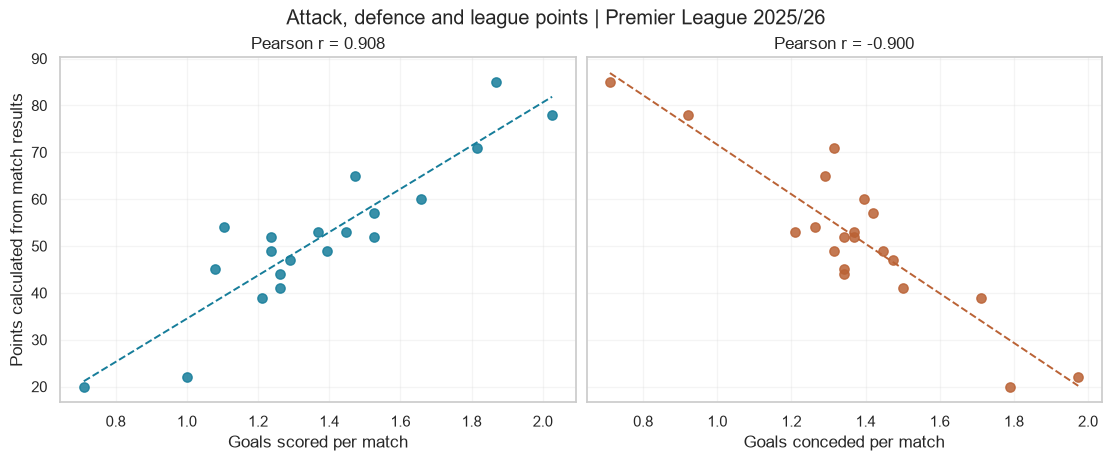

In [25]:
# Create side-by-side scatter plots for goals scored and conceded per match against league points
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True, layout="constrained")
for ax, metric, label, colour in zip(
    axes, ["GoalsPerMatch", "ConcededPerMatch"],
    ["Goals scored per match", "Goals conceded per match"], ["#167d9a", "#ba6235"]):
    x = summary[metric]
    y = summary["Points"]
    ax.scatter(x, y, color=colour, s=45, alpha=0.85)
    slope, intercept = np.polyfit(x, y, 1)
    grid = np.linspace(x.min(), x.max(), 100)
    ax.plot(grid, slope * grid + intercept, "--", color=colour, linewidth=1.4)
    ax.set_xlabel(label)
    ax.set_title(f"Pearson r = {x.corr(y):.3f}")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Points calculated from match results")
fig.suptitle("Attack, defence and league points | Premier League 2025/26")
plt.show()

Goals directly determine match points by definition, so this is a same-season descriptive association. **Correlation does not prove causation**.

## Section 5: Home and Away Performance Comparisons

**Purpose**: This section compares home and away match outcomes, attacking activity and disciplinary records within the same fixture. Descriptive summaries and visualisations are followed by exploratory paired t-tests for attacking metrics, to examine whether home teams show systematic performance differences relative to away teams.

### Section 5.1 Compare Match Outcomes

Count home wins, draws and away wins, then calculate each result type as a percentage of all fixtures. This establishes baseline home advantage context before the deeper performance comparisons.

In [27]:
# Count match results and convert counts to percentage of total fixtures
result_counts = matches.FTR.value_counts().reindex(["H", "D", "A"], fill_value=0)
outcome_table = pd.DataFrame({"Matches": result_counts, "Percentage": result_counts / len(matches) * 100})
outcome_table.index = ["Home win", "Draw", "Away win"]
display(outcome_table.round(2))

,Matches,Percentage
Home win,162,42.63
Draw,104,27.37
Away win,114,30.00


### Section 5.2 Compare Attacking Statistics

Compare average shots, shots on target and corners for home and away sides. The numerical table reports exact mean values, while the grouped bar chart makes the magnitude of home/away differences easier to visualise.

,Home,Away
Shots,13.839,11.158
Shots on target,4.503,3.871
Corners,5.395,4.603


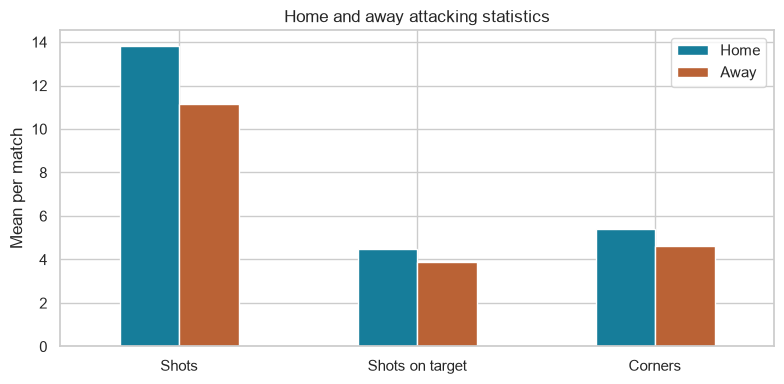

In [28]:
# Calculate mean attacking metrics and create grouped bar chart for home vs away teams
attack_pairs = {"Shots": ("HS", "AS"), "Shots on target": ("HST", "AST"), "Corners": ("HC", "AC")}
attack_stats = pd.DataFrame({label: {"Home": matches[h].mean(), "Away": matches[a].mean()}
                             for label, (h, a) in attack_pairs.items()}).T
display(attack_stats.round(3))
ax = attack_stats.plot.bar(figsize=(8, 4), color=["#167d9a", "#ba6235"], rot=0)
ax.set(title="Home and away attacking statistics", ylabel="Mean per match", xlabel="")
plt.tight_layout()
plt.show()

### Section 5.3 Inspect Paired Differences

Calculate **home-minus-away differences within each individual match**. We examine the distribution, spread and extreme values of these differences before running paired t-tests.

,count,mean,std,min,25%,50%,75%,max
Shots,380.0,2.682,7.818,-24.0,-2.0,3.0,8.0,28.0
Shots on target,380.0,0.632,3.294,-9.0,-2.0,1.0,3.0,10.0
Corners,380.0,0.792,4.397,-14.0,-2.0,1.0,4.0,12.0


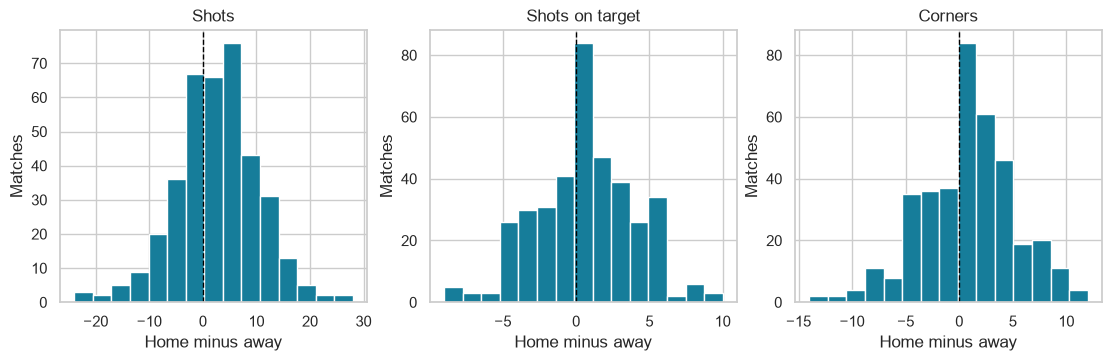

In [29]:
# Compute home-minus-away differences for each match and plot histograms to examine distribution
# One difference per match: home minus away.
differences = pd.DataFrame({label: matches[h] - matches[a] for label, (h, a) in attack_pairs.items()})
display(differences.describe().T.round(3))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), layout="constrained")
for ax, label in zip(axes, differences.columns):
    ax.hist(differences[label], bins=15, color="#167d9a", edgecolor="white")
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set(title=label, xlabel="Home minus away", ylabel="Matches")
plt.show()

### Section 5.4 Perform Paired t-tests

Paired two-sided t-tests evaluate whether the average within-match difference equals zero for each attacking metric. P-values, 95% confidence intervals and Cohen's d effect sizes are reported. A Holm correction is applied to adjust p-values to account for multiple testing across the three comparisons.

Hypotheses:<br><br>
$H_0$ : The mean within-match home-away difference $= 0$
<br>
<br>
$H_1$ : The mean within-match home-away difference $\neq 0$

Note: The pairing is per match. Repeated teams across fixtures introduce some dependence, so these p-values and confidence intervals are exploratory and rely on an independence approximation. The 95% intervals are pointwise and not simultaneous.

In [30]:
# Run paired t-tests, calculate effect sizes and apply Holm correction for multiple testing
test_rows = []
for label, (h, a) in attack_pairs.items():
    d = differences[label]
    n = len(d)
    mean_diff = d.mean()
    sd_diff = d.std(ddof=1)
    se = sd_diff / np.sqrt(n)
    margin = t.ppf(0.975, df=n - 1) * se
    result = ttest_rel(matches[h], matches[a], alternative="two-sided")
    test_rows.append({"Metric": label, "N pairs": n, "Home mean": matches[h].mean(),
        "Away mean": matches[a].mean(), "Mean H-A": mean_diff,
        "CI95 lower": mean_diff - margin, "CI95 upper": mean_diff + margin,
        "t statistic": result.statistic, "df": n - 1, "Raw p": result.pvalue,
        "Cohen dz": mean_diff / sd_diff})
tests = pd.DataFrame(test_rows).set_index("Metric")

# Holm adjustment controls multiple testing across the three attacking tests,
# assuming the underlying p-values are valid.
pvalues = tests["Raw p"].to_numpy()
order = np.argsort(pvalues)
adjusted = np.empty(len(pvalues))
adjusted[order] = np.minimum(1, np.maximum.accumulate(pvalues[order] * (len(pvalues) - np.arange(len(pvalues)))))
tests["Holm p"] = adjusted
tests["Holm p < 0.05"] = tests["Holm p"] < 0.05
assert np.isfinite(tests.select_dtypes(include="number")).all().all()
assert ((tests["Holm p"] >= tests["Raw p"] - 1e-15) & (tests["Holm p"] <= 1)).all()
display(tests.style.format({"Home mean":"{:.3f}", "Away mean":"{:.3f}", "Mean H-A":"{:.3f}",
    "CI95 lower":"{:.3f}", "CI95 upper":"{:.3f}", "t statistic":"{:.3f}",
    "Raw p":"{:.3g}", "Holm p":"{:.3g}", "Cohen dz":"{:.3f}"}))

,N pairs,Home mean,Away mean,Mean H-A,CI95 lower,CI95 upper,t statistic,df,Raw p,Cohen dz,Holm p,Holm p < 0.05
Metric,,,,,,,,,,,,
Shots,380,13.839,11.158,2.682,1.893,3.470,6.687,379,8.2e-11,0.343,2.46e-10,True
Shots on target,380,4.503,3.871,0.632,0.299,0.964,3.738,379,0.000214,0.192,0.000429,True
Corners,380,5.395,4.603,0.792,0.349,1.236,3.511,379,0.000499,0.180,0.000499,True


The 95% confidence intervals for all three metrics do not cross zero. We reject the null hypothesis for each test: there is statistically significant evidence that home teams produce more shots, shots on target and corners within matches.

### Section 5.5 Compare Disciplinary Statistics

Summarise yellow and red cards using means, medians, maxima and the percentage of observations with zero cards. This comparison remains descriptive because card counts, especially red cards, are sparse and skewed. No t-tests are applied here.

In [31]:
# Generate descriptive summary statistics for yellow and red cards for home and away teams
card_rows = []
for label, h, a in [("Yellow cards", "HY", "AY"), ("Red cards", "HR", "AR")]:
    card_rows.append({"Card": label, "Home mean": matches[h].mean(), "Away mean": matches[a].mean(),
        "Home median": matches[h].median(), "Away median": matches[a].median(),
        "Home maximum": matches[h].max(), "Away maximum": matches[a].max(),
        "Home zero %": matches[h].eq(0).mean()*100, "Away zero %": matches[a].eq(0).mean()*100,
        "Mean H-A": (matches[h]-matches[a]).mean()})
display(pd.DataFrame(card_rows).set_index("Card").round(3))

,Home mean,Away mean,Home median,Away median,Home maximum,Away maximum,Home zero %,Away zero %,Mean H-A
Card,,,,,,,,,
Yellow cards,1.666,2.082,2.0,2.0,5,6,18.684,11.316,-0.416
Red cards,0.050,0.053,0.0,0.0,2,1,95.526,94.737,-0.003


Since red card counts are heavily skewed and rare, we keep this section purely descriptive. No statistical testing is performed, and we draw **no conclusions about referee bias**.

## Section 6: Player-Level Exploration

**Purpose**: This section explores the association between player age and scoring performance. The analysis accounts for playing position and minutes played, to compare scoring output among players with different positional roles and game participation levels.

### Section 6.1 Explore Age and Scoring

We first examine the relationship between player age and total goals scored, then standardise scoring output by calculating goals per 90 minutes to adjust for unequal playing time. Players are grouped by primary playing position. A minimum minutes threshold is applied to filter out players with limited game time, and we test several alternative cut-off values to investigate whether the filtering choice changes the observed statistical relationships.

In [32]:
# Filter valid player records, calculate goals per 90 minutes and apply minimum playing-time filter
# Keep the original age-versus-total-goals exploration, then account for exposure.
valid_player = epl[["Age", "Min", "Gls"]].notna().all(axis=1) & epl.Min.gt(0) & epl.Pos.notna()
assert (epl.loc[valid_player, ["Min", "Gls"]] >= 0).all().all()
scoring = epl.loc[valid_player].copy()
scoring["PrimaryPosition"] = scoring.Pos.str.split(",").str[0]
scoring = scoring.loc[scoring.PrimaryPosition.ne("GK")].copy()
scoring["GoalsPer90"] = scoring.Gls * 90 / scoring.Min
minimum_minutes = 900  # Ten full matches; a transparent small-exposure filter.
regulars = scoring.loc[scoring.Min >= minimum_minutes].copy()
print("EPL player records:", len(epl))
print("Excluded for missing age/minutes/goals/position or zero minutes:", (~valid_player).sum())
print("Eligible outfield records:", len(scoring))
print("Outfield records with at least 900 minutes:", len(regulars))
display(regulars.groupby("PrimaryPosition")[["Age", "Min", "Gls", "GoalsPer90"]].agg(["count", "mean", "median"]).round(3))

EPL player records: 551
Excluded for missing age/minutes/goals/position or zero minutes: 0
Eligible outfield records: 511
Outfield records with at least 900 minutes: 315


Age                  Min                     Gls         \
                count    mean median count      mean  median count   mean   
PrimaryPosition                                                             
DF                122  25.811   25.0   122  2082.311  1933.0   122  1.016   
FW                 44  26.068   25.0    44  1750.205  1653.5    44  7.273   
MF                149  24.758   25.0   149  1962.315  1841.0   149  3.262   

                       GoalsPer90                
                median      count   mean median  
PrimaryPosition                                  
DF                 1.0        122  0.041  0.030  
FW                 6.0         44  0.340  0.324  
MF                 2.0        149  0.145  0.116

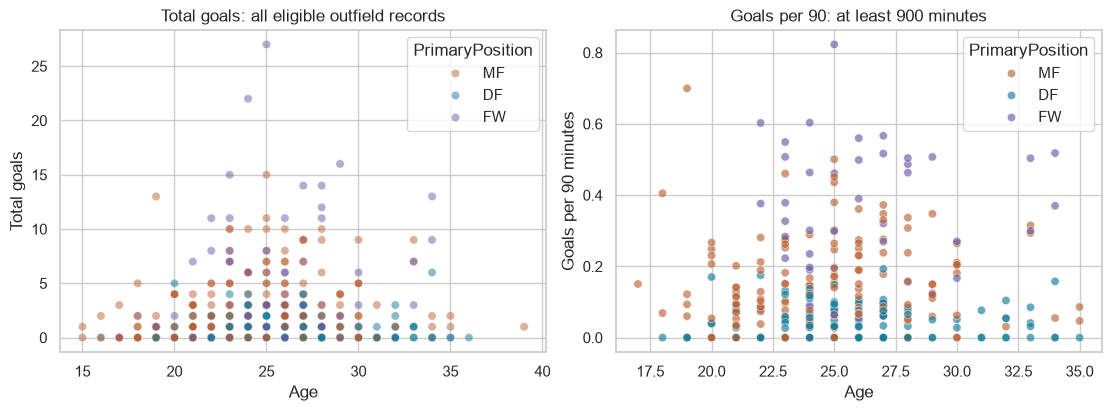

In [33]:
# Generate side-by-side scatter plots showing scoring metrics against age, coloured by player position
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
palette = {"DF":"#167d9a", "MF":"#ba6235", "FW":"#6e59a5"}
sns.scatterplot(data=scoring, x="Age", y="Gls", hue="PrimaryPosition", palette=palette, alpha=0.5, ax=axes[0])
axes[0].set(title="Total goals: all eligible outfield records", xlabel="Age", ylabel="Total goals")
sns.scatterplot(data=regulars, x="Age", y="GoalsPer90", hue="PrimaryPosition", palette=palette, alpha=0.65, ax=axes[1])
axes[1].set(title="Goals per 90: at least 900 minutes", xlabel="Age", ylabel="Goals per 90 minutes")
plt.show()

In [34]:
# Descriptive sensitivity check for the playing-time threshold.
# Sensitivity test: compute Pearson correlation between age and goals per 90 across multiple playing-time thresholds
threshold_rows = []
for cutoff in [450, 900, 1350]:
    subset = scoring.loc[scoring.Min >= cutoff]
    for position, group in subset.groupby("PrimaryPosition"):
        threshold_rows.append({"Minimum minutes": cutoff, "Position": position, "Records": len(group),
            "Age vs goals/90 (Pearson r)": group.Age.corr(group.GoalsPer90)})
display(pd.DataFrame(threshold_rows).round(3))

,Minimum minutes,Position,Records,Age vs goals/90 (Pearson r)
0,450,DF,139,-0.038
1,450,FW,56,0.106
2,450,MF,182,0.034
3,900,DF,122,-0.008
4,900,FW,44,0.119
5,900,MF,149,0.030
6,1350,DF,96,-0.035
7,1350,FW,31,-0.021
8,1350,MF,115,-0.007


This is exploratory descriptive analysis only and cannot prove that age causes differences in scoring output. Using per-90 scoring rates and splitting samples by playing position partly mitigates comparability issues, but the analysis still does not control for team quality, tactical role or selection bias. Players who transfer clubs may appear multiple times as separate records. All data source URLs and collection dates must be recorded in the research proposal.